# AG News: pretrained model ranking prediction

Adapted from `Ohsumed/RankPredict.ipynb`. Uses only the local AG News **train** split.
Each article has one of four labels. `document_id` records its original train row;
`labels` contains a singleton list for compatibility with the pairwise statistics.
The test split is reserved. Sampling and metric settings follow the reference notebook.
Bootstrap standard deviations describe different-label score resampling conditional
on the fixed same-label scores, not full document-level uncertainty.


### Original-code audit before this experiment
- Four raw class IDs map one-to-one to singleton label-name lists, not one-hot bit sets.
- Original pair functions passed a direct equality-mask check: 4,979 same + 14,921 different = 19,900 unique pairs on the original seed-42 sample.
- Encoders receive text only; labels and F1 ranks are used downstream.
- Original plotting selected five models and pooled three samples. Between-model separation alone does not establish label discrimination.
- The source has 79 repeated normalized texts, retained unchanged; duplicates in each new sample are reported.
- This notebook rechecks encoding and pair counts, then verifies saved real-embedding distributions and reports a shuffled-label control.


In [1]:
%matplotlib inline
from pathlib import Path
from collections import defaultdict
from itertools import combinations
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_from_disk

# Support running from the project root or the ACGNews directory.
PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / "ACGNews" / "data" / "ag_news").is_dir():
    PROJECT_DIR = PROJECT_DIR / "ACGNews"
DATA_DIR = PROJECT_DIR / "data" / "ag_news"
RESULTS_DIR = PROJECT_DIR / "results" / "rank_prediction"
ROOT = PROJECT_DIR.parent


In [2]:
dataset = load_from_disk(str(DATA_DIR))
train_dataset = dataset["train"]
label_names = train_dataset.features["label"].names
assert label_names == ["World", "Sports", "Business", "Sci/Tech"]

df = train_dataset.to_pandas()
# IDs refer to original train rows, before cleaning or sampling.
df["document_id"] = [f"ag_news_train_{i:06d}" for i in range(len(df))]
df = df.dropna(subset=["text", "label"]).copy()
df["training_text"] = df["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["training_text"].ne("")].copy()
assert df["label"].isin(range(len(label_names))).all()
# Preserve AG News single-label semantics; do not merge conflicting labels.
df["labels"] = df["label"].map(lambda value: [label_names[int(value)]])
print("Repeated normalized texts:", df["training_text"].duplicated().sum())
print("Duplicate texts are retained to preserve the source train dataset.")
training_df = df[["document_id", "training_text", "labels"]].reset_index(drop=True)
assert training_df["document_id"].is_unique
assert training_df["labels"].map(len).eq(1).all()
assert set(training_df["labels"].explode()) == set(label_names)
print("Training documents:", len(training_df))
print("Label counts:")
print(training_df["labels"].explode().value_counts())
display(training_df.head())


Repeated normalized texts: 79
Duplicate texts are retained to preserve the source train dataset.
Training documents: 120000
Label counts:
labels
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


,document_id,training_text,labels
0,ag_news_train_000000,Wall St. Bears Claw Back Into the Black (Reute...,[Business]
1,ag_news_train_000001,Carlyle Looks Toward Commercial Aerospace (Reu...,[Business]
2,ag_news_train_000002,Oil and Economy Cloud Stocks' Outlook (Reuters...,[Business]
3,ag_news_train_000003,Iraq Halts Oil Exports from Main Southern Pipe...,[Business]
4,ag_news_train_000004,"Oil prices soar to all-time record, posing new...",[Business]


In [3]:
TEXT_COL = "training_text"
LABEL_COL = "labels"

SAMPLE_SIZE = 200
RANDOM_SEED = 20261028
NUM_REPETITIONS = 10
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]
from datetime import datetime
import json
import pickle
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: select the RTX 5080 .venv Python kernel.")
print("GPU:", torch.cuda.get_device_name(0))
torch.backends.cuda.matmul.allow_tf32 = False
OUTPUT_DIR = PROJECT_DIR / "results" / ("uncertainty10_gpu_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Results directory:", OUTPUT_DIR.resolve())


GPU: NVIDIA GeForce RTX 5080
Results directory: /home/amyliu/Desktop/GR/ACGNews/results/uncertainty10_gpu_20261025_174025


In [4]:
def asymmetry_eta(x, bandwidth=None):
    """Original leave-one-out eta estimator, evaluated in float64 on CUDA.

    Row chunks limit GPU memory; strict empirical CDF handles ties exactly.
    """
    with torch.inference_mode():
        x = torch.as_tensor(np.asarray(x, dtype=float), device="cuda", dtype=torch.float64)
        x = x[~torch.isnan(x)]
        n = x.numel()
        if n < 3:
            return np.nan
        s = x.std(correction=1)
        q = torch.quantile(x, torch.tensor([0.25, 0.75], device=x.device, dtype=x.dtype))
        iqr = q[1] - q[0]
        sigma = torch.minimum(s, iqr / 1.349) if iqr.item() > 0 else s
        if torch.isclose(sigma, torch.zeros_like(sigma), rtol=1e-5, atol=1e-8).item():
            sigma = s if s.item() > 0 else x.new_tensor(1.0)
        h = x.new_tensor(bandwidth) if bandwidth is not None else 0.9 * sigma * n ** (-1 / 5)
        if h.item() <= 0:
            h = 1.06 * (s if s.item() > 0 else x.new_tensor(1.0)) * n ** (-1 / 5)
        f_hat = torch.empty_like(x)
        normalizer = (2 * np.pi) ** -0.5
        for start in range(0, n, 128):
            end = min(start + 128, n)
            kernel = (x.unsqueeze(0) - x[start:end].unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel[torch.arange(end-start, device=x.device), torch.arange(start,end,device=x.device)] = 0
            f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
        F_hat = torch.searchsorted(torch.sort(x).values, x, right=False).to(x.dtype) / (n - 1)
        if f_hat.std(correction=1).item() == 0 or F_hat.std(correction=1).item() == 0:
            return np.nan
        return (-torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]).item()


In [5]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):
    # Preserve NumPy bin edges and boundary conventions; count and reduce on GPU.
    edges = np.histogram_bin_edges(dist1, bins=bins, range=value_range)
    edges = torch.as_tensor(edges, device="cuda", dtype=torch.float64)
    def histogram(values):
        values = torch.as_tensor(np.asarray(values), device="cuda", dtype=torch.float64)
        valid = (values >= edges[0]) & (values <= edges[-1])
        indices = torch.bucketize(values[valid], edges, right=True) - 1
        indices.clamp_(max=edges.numel()-2)
        counts = torch.bincount(indices, minlength=edges.numel()-1).to(torch.float64)
        return counts / counts.sum()
    p, q = histogram(dist1), histogram(dist2)
    return (0.5 * ((p-q).square() / (p+q+eps)).sum()).item()


In [6]:
def create_cosine_similarity_matrix(embeddings):
    with torch.inference_mode():
        normalized = F.normalize(embeddings.detach().to("cuda", dtype=torch.float32), p=2, dim=1)
        return (normalized @ normalized.T).cpu().numpy()


In [7]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [8]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [9]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [10]:
def prepare_sampling_dataframe(
    training_df,
):
    result = training_df[
        [
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    ].copy()

    # Remove missing essential values
    result = result.dropna(
        subset=[
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    )

    # Remove empty text
    result = result[
        result[TEXT_COL]
        .astype(str)
        .str.strip()
        .ne("")
    ].copy()

    # One row per document
    result = result.drop_duplicates(
        subset=["document_id"],
        keep="first",
    )

    # Character count: descriptive only
    result["char_length"] = (
        result[TEXT_COL]
        .str.len()
    )

    # Word count: used for quantile sampling
    result["length"] = (
        result[TEXT_COL]
        .str.split()
        .str.len()
    )

    result = result.reset_index(
        drop=True
    )

    print(
        "Shape:",
        result.shape,
    )

    print(
        "Minimum word count:",
        result["length"].min(),
    )

    print(
        "Average word count:",
        result["length"].mean(),
    )

    print(
        "Maximum word count:",
        result["length"].max(),
    )

    print(
        "Number of labels:",
        result[LABEL_COL]
        .explode()
        .nunique(),
    )

    return result

In [11]:
sampling_df = (
    prepare_sampling_dataframe(
        training_df
    )
)

Shape: (120000, 5)
Minimum word count: 8
Average word count: 37.84745
Maximum word count: 177
Number of labels: 4


In [12]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    text_col="training_text",
):
    sampling_pool = (
        df.copy()
        .reset_index(drop=True)
    )

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool[text_col]
            .astype(str)
            .str.split()
            .str.len()
        )

    # The actual number of groups cannot exceed:
    # 1. requested quantiles
    # 2. sample size
    # 3. number of unique text lengths
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    # Create length groups from the whole dataset
    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"]
        .nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    sampled_parts = []

    # Sample approximately the same number
    # from every length group
    for group_number, group_df in (
        sampling_pool.groupby(
            "_length_group",
            observed=True,
        )
    ):
        number_to_sample = min(
            samples_per_group,
            len(group_df),
        )

        sampled_part = group_df.sample(
            n=number_to_sample,
            random_state=(
                random_seed
                + int(group_number)
            ),
        )

        sampled_parts.append(
            sampled_part
        )

    sampled_df = pd.concat(
        sampled_parts,
        axis=0,
    )

    # Fill remaining positions if qcut produced
    # fewer groups or some groups were too small
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = (
            sampling_pool.drop(
                index=sampled_df.index
            )
        )

        additional_samples = (
            remaining_pool.sample(
                n=remaining_count,
                random_state=random_seed,
            )
        )

        sampled_df = pd.concat(
            [
                sampled_df,
                additional_samples,
            ],
            axis=0,
        )

    # Shuffle the final sample
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(
            columns=["_length_group"]
        )
        .reset_index(drop=True)
    )

    print(
        "Original dataset size:",
        len(sampling_pool),
    )
    print(
        "Actual sample size:",
        len(sampled_df),
    )
    print(
        "Minimum word count:",
        sampled_df["length"].min(),
    )
    print(
        "Average word count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum word count:",
        sampled_df["length"].max(),
    )
    print(
        "Number of represented labels:",
        sampled_df["labels"]
        .explode()
        .nunique(),
    )

    return sampled_df

In [13]:
sampled_df = sample_from_length_groups(
    df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED,
    text_col=TEXT_COL,
)

Original dataset size: 120000
Actual sample size: 200
Minimum word count: 8
Average word count: 39.12
Maximum word count: 121
Number of represented labels: 4


In [14]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [15]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = torch.as_tensor(same_scores, device="cuda", dtype=torch.float64).mean().item()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = torch.as_tensor(sampled_diff_scores, device="cuda", dtype=torch.float64).mean().item()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)
        if (b + 1) % 100 == 0:
            print(f"Bootstrap {b + 1}/{n_bootstrap}", flush=True)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [16]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # AG News text and singleton label lists
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["World"], ["Sports"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
            sampled_df["document_id"]
            .tolist()
        ),

        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [17]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=10,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    output_dir=None,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / "run_config.json").write_text(json.dumps({
            "statistics_device": "cuda", "dataset": "ACGNews",
            "master_seed": master_seed, "repetition_seeds": repetition_seeds.tolist(),
            "num_repetitions": num_repetitions, "models": models,
            "sample_size_requested": sample_size, "num_quantiles": num_quantiles,
            "batch_size": batch_size, "max_token": max_token,
            "n_bootstrap": n_bootstrap, "bins": bins, "value_range": value_range,
            "eta_bandwidth": eta_bandwidth, "text_col": text_col, "label_col": label_col,
        }, indent=2))

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                ),
                text_col=text_col,
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        if output_dir is not None:
            sampled_df.to_csv(output_dir / f"sample_{repetition + 1:02d}.csv", index=False)

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary["actual_sample_size"] = len(sampled_df)
            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

            if output_dir is not None:
                model_file = model_name.replace("/", "__")
                with (output_dir / f"rep_{repetition + 1:02d}_{model_file}.pkl").open("wb") as handle:
                    pickle.dump(result, handle, protocol=pickle.HIGHEST_PROTOCOL)
                pd.DataFrame(summary_results).to_csv(output_dir / "summary_per_run.csv", index=False)
                print(f"Saved {len(summary_results)}/{num_repetitions * len(models)} model runs", flush=True)

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [18]:
# Label encoding audit: raw IDs must map one-to-one to singleton class names.
assert df["labels"].map(len).eq(1).all()
assert all(labels == [label_names[int(value)]] for labels, value in zip(df.labels, df.label))
assert training_df.document_id.is_unique
assert set(training_df.labels.explode()) == set(label_names)
assert sampled_df.document_id.nunique() == SAMPLE_SIZE
counts = sampled_df.labels.explode().value_counts()
expected_same = int(sum(count*(count-1)//2 for count in counts))
expected_total = SAMPLE_SIZE*(SAMPLE_SIZE-1)//2
# Test original pair-selection functions against direct class-equality masks.
rng_audit = np.random.default_rng(20261028)
probe = torch.tensor(rng_audit.normal(size=(SAMPLE_SIZE,32)),dtype=torch.float32)
probe_labels = sampled_df.labels.tolist()
probe_matrix = create_cosine_similarity_matrix(probe)
ii,jj = np.triu_indices(SAMPLE_SIZE,k=1)
classes = np.array([label[0] for label in probe_labels])
same_mask = classes[ii] == classes[jj]
scores_same,_ = calculate_within_label_cosine_distribution(probe,probe_labels)
scores_diff,_ = calculate_between_label_cosine_distribution(probe,probe_labels)
np.testing.assert_allclose(scores_same,probe_matrix[ii[same_mask],jj[same_mask]],atol=1e-6)
np.testing.assert_allclose(scores_diff,probe_matrix[ii[~same_mask],jj[~same_mask]],atol=1e-6)
assert len(scores_same) == expected_same
assert len(scores_same)+len(scores_diff) == expected_total == 19900
label_audit = dict(singleton_encoding=True,distinct_classes=label_names,train_documents=len(training_df),
    duplicate_normalized_texts=int(df.training_text.duplicated().sum()),sample_size=SAMPLE_SIZE,
    sample_label_counts=counts.to_dict(),same_pairs=expected_same,different_pairs=expected_total-expected_same,
    direct_pair_mask_check="PASS",test_split_used=False)
(OUTPUT_DIR / "label_encoding_audit.json").write_text(json.dumps(label_audit,indent=2))
display(label_audit)


Total unique within-label document pairs: 4943
Number of label-set pair types: 6
Total unique between-label document pairs: 14957


{'singleton_encoding': True,
 'distinct_classes': ['World', 'Sports', 'Business', 'Sci/Tech'],
 'train_documents': 120000,
 'duplicate_normalized_texts': 79,
 'sample_size': 200,
 'sample_label_counts': {'Sci/Tech': 57,
  'World': 50,
  'Sports': 49,
  'Business': 44},
 'same_pairs': 4943,
 'different_pairs': 14957,
 'direct_pair_mask_check': 'PASS',
 'test_split_used': False}

In [19]:
results = metric_collect(
    grouped_df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=NUM_REPETITIONS,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
)

Repetition 1/10
Repetition seed: 709887878
Original dataset size: 120000
Actual sample size: 200
Minimum word count: 16
Average word count: 38.765
Maximum word count: 87
Number of represented labels: 4
Actual sample size: 200
Label counts:
labels
Business    43
Sci/Tech    63
Sports      47
World       47
Name: count, dtype: int64
Number of represented labels: 4

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 5018
Number of label-set pair types: 6
Total unique between-label document pairs: 14882
Same-label target size: 5018
Different-label pair types: 6
Base sample per diff-label pair: 836
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.7073715077946984
Different mean: 0.6526188069308609
Mean gap: 0.0547527008638374
Same eta: -0.05670986310638527
Different eta: -0.09613237059413114
Different |eta|: 0.09613237059413114
Eta gap: 0.03942250748774589
Chi-square distance: 0.1510072262731742
Chi-square bootstrap std: 0.004131354195183255
Saved 1/70 model runs

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (201 outputs left out)

Model: recobo/agriculture-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 5129
Number of label-set pair types: 6
Total unique between-label document pairs: 14771
Same-label target size: 5129
Different-label pair types: 6
Base sample per diff-label pair: 854
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.8611965845565066
Different mean: 0.844494477640295
Mean gap: 0.01670210691621178
Same eta: -0.2719050924485271
Different eta: -0.2277254038612269
Different |eta|: 0.2277254038612269
Eta gap: -0.04417968858730027
Chi-square distance: 0.059156821147640946
Chi-square bootstrap std: 0.0029581834749050555
Saved 69/70 model runs

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 5129
Number of label-set pair types: 6
Total unique between-label document pairs: 14771
Same-label target size: 5129
Different-label pair types: 6
Base sample per diff-label pair: 854
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.8947623588695328
Different mean: 0.890167509474585
Mean gap: 0.004594849394947735
Same eta: -0.44676142261977025
Different eta: -0.31441766225662254
Different |eta|: 0.31441766225662254
Eta gap: -0.13234376036314768
Chi-square distance: 0.011717634999027922
Chi-square bootstrap std: 0.0014258805182453989
Saved 70/70 model runs


In [20]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.707372,-0.056710,0.056710,5018,0.652619,0.000810,-0.096132,0.020579,0.096132,...,50,"(-1, 1)",64,128,709887878,1,200,100,4,200
1,allenai/scibert_scivocab_uncased,0.837671,-0.280201,0.280201,5018,0.818244,0.000581,-0.247604,0.021673,0.247604,...,50,"(-1, 1)",64,128,709887878,1,200,100,4,200
2,nlpaueb/legal-bert-base-uncased,0.899009,-0.292574,0.292574,5018,0.885418,0.000340,-0.253906,0.022507,0.253906,...,50,"(-1, 1)",64,128,709887878,1,200,100,4,200
3,ahmedrachid/FinancialBERT,0.821492,-0.205035,0.205035,5018,0.798730,0.000703,-0.227853,0.021130,0.227853,...,50,"(-1, 1)",64,128,709887878,1,200,100,4,200
4,Lianglab/PharmBERT-uncased,0.774735,-0.223830,0.223830,5018,0.746584,0.000720,-0.287156,0.020274,0.287156,...,50,"(-1, 1)",64,128,709887878,1,200,100,4,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.895325,-0.229270,0.229270,5129,0.883688,0.000309,-0.166787,0.021973,0.166787,...,50,"(-1, 1)",64,128,2406784345,10,200,100,4,200
66,ahmedrachid/FinancialBERT,0.820576,-0.241354,0.241354,5129,0.799284,0.000645,-0.236405,0.022409,0.236405,...,50,"(-1, 1)",64,128,2406784345,10,200,100,4,200
67,Lianglab/PharmBERT-uncased,0.763009,-0.363922,0.363922,5129,0.736322,0.000858,-0.318867,0.020613,0.318867,...,50,"(-1, 1)",64,128,2406784345,10,200,100,4,200
68,recobo/agriculture-bert-uncased,0.861197,-0.271905,0.271905,5129,0.844494,0.000444,-0.227725,0.020851,0.227725,...,50,"(-1, 1)",64,128,2406784345,10,200,100,4,200


In [21]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)
metric_summary_df.to_csv(OUTPUT_DIR / "metric_summary.csv", index=False)


,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.767800,0.005002,0.741090,0.006690,0.000804,-0.253568,0.056957,0.253568,0.056957,...,0.020844,0.038244,0.019473,0.059347,0.012776,0.003028,4975.6,4975.6,4.0,10
1,ahmedrachid/FinancialBERT,0.820014,0.003066,0.798093,0.004670,0.000684,-0.272647,0.062764,0.272647,0.062764,...,0.021958,0.048230,0.040849,0.052726,0.012713,0.002825,4975.6,4975.6,4.0,10
2,allenai/scibert_scivocab_uncased,0.836564,0.003045,0.817911,0.003605,0.000550,-0.306255,0.078379,0.306255,0.078379,...,0.021459,0.051114,0.024610,0.062138,0.012258,0.003011,4975.6,4975.6,4.0,10
3,google-bert/bert-base-uncased,0.703229,0.004230,0.653723,0.005013,0.000853,-0.060931,0.069995,0.074437,0.053552,...,0.021346,0.086901,0.070085,0.127335,0.022035,0.003883,4975.6,4975.6,4.0,10
4,nlpaueb/legal-bert-base-uncased,0.897520,0.001595,0.885468,0.001615,0.000330,-0.233213,0.074558,0.233213,0.074558,...,0.021681,0.047276,0.015850,0.056080,0.012660,0.002905,4975.6,4975.6,4.0,10
5,recobo/agriculture-bert-uncased,0.863784,0.001923,0.845524,0.003062,0.000474,-0.312152,0.060941,0.312152,0.060941,...,0.021630,0.051751,0.031523,0.069080,0.015895,0.003197,4975.6,4975.6,4.0,10
6,recobo/chemical-bert-uncased,0.898411,0.002229,0.892325,0.002489,0.000400,-0.429337,0.034898,0.429337,0.034898,...,0.020664,0.046564,0.033914,0.013305,0.005601,0.001529,4975.6,4975.6,4.0,10


In [22]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,2,2,5,4,7,4
1,ahmedrachid/FinancialBERT,5,3,3,3,4,5,4,6
2,allenai/scibert_scivocab_uncased,4,4,4,4,3,3,3,3
3,google-bert/bert-base-uncased,7,1,1,1,7,7,1,1
4,nlpaueb/legal-bert-base-uncased,2,6,6,6,6,6,5,5
5,recobo/agriculture-bert-uncased,3,5,5,5,2,2,2,2
6,recobo/chemical-bert-uncased,1,7,7,7,1,1,6,7


## Ten-sample uncertainty experiment

Each repetition draws a fresh length-stratified sample shared by all seven models.
Original ACGNews train-only sampling pool, word-length strata, 200 requested documents, 128 tokens,
and 1,000 internal bootstrap draws are retained. Exact samples and seeds are saved.
GPU calculations use the validated Financial implementation (float64 KDE in chunks).

`sampling_std` describes variation between document samples; `bootstrap_std_mean`
describes conditional variation with documents fixed. Neither is a 95% interval.
The t intervals below are approximate intervals for the **mean over repeated sampling**,
conditional on this dataset and procedure; they are not intervals for a future run or F1.
Ten repetitions are a pilot, not a guarantee of coverage.

All formulas, normalization rules and F1 targets are loaded without new grid search.
The held-out ACGNews formula is the main generalization check; the full-fit formula
has seen ACGNews and is exploratory. F1 training uncertainty is not included.



AG News uses four singleton labels; same/different pairs are determined by exact class equality. Duplicate source texts are retained as in the original notebook.


In [23]:
from scipy.stats import rankdata, spearmanr, t
from IPython.display import display, Markdown
import seaborn as sns
MODEL_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "nlpaueb/legal-bert-base-uncased": "LegalBERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "Lianglab/PharmBERT-uncased": "PharmBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT",
    "recobo/chemical-bert-uncased": "ChemicalBERT",
}
METRICS = ["SameMean", "DffMean", "SameAbsEta", "DiffAbsEta", "Chi2Distance"]
RAW = ["same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta", "chi2_distance"]
GRID = ROOT / "GridSearch" / "results_nested_five_required"
target = pd.read_csv(ROOT / "GridSearch" / "result1.csv")
target = target.loc[target.Dataset.eq("ACGNews")].set_index("ModelName").sort_index()
order = target.index.tolist()
assert len(summary_df) == 70 and summary_df.groupby("repetition").model.nunique().eq(7).all()
assert set(MODEL_NAMES.values()) == set(order)
uncertainty_rows = []
for model, g in summary_df.groupby("model"):
    for metric in RAW:
        values = g[metric].to_numpy(float)
        mean, sd = values.mean(), values.std(ddof=1)
        half = t.ppf(.975, len(values)-1) * sd / np.sqrt(len(values))
        uncertainty_rows.append(dict(model=MODEL_NAMES[model], metric=metric,
            mean=mean, sampling_std=sd, minimum=values.min(), maximum=values.max(),
            mean_t95_low=mean-half, mean_t95_high=mean+half, repetitions=len(values)))
uncertainty_df = pd.DataFrame(uncertainty_rows)
uncertainty_df.to_csv(OUTPUT_DIR / "uncertainty_summary.csv", index=False)
display(Markdown("### Five metrics: mean, sampling SD and approximate mean intervals"))
display(uncertainty_df.round(6))
# Copy sources to preserve the exact target and formulas used in this analysis.
target.to_csv(OUTPUT_DIR / "f1_target_snapshot.csv")
final = json.loads((GRID / "final_formula.json").read_text())
fold = pd.read_csv(GRID / "outer_fold_results.csv")
fold = fold.loc[fold.HeldOutDataset.eq("ACGNews") & fold.Procedure.eq("selected")].iloc[0]
coeff = pd.read_csv(GRID / "outer_coefficients.csv")
coeff = coeff.loc[coeff.HeldOutDataset.eq("ACGNews") & coeff.Procedure.eq("selected")].set_index("Metric")
CONFIGS = {
    "held_out_ACGNews": (fold.Standardization, coeff.loc[METRICS, "Coefficient"].to_numpy(float)),
    "full_fit_exploratory": (final["Standardization"], np.array([final["Coefficients"][m] for m in METRICS])),
}
# Exact existing grid-search deployment rule: normalize across seven candidate models
# within each sample. No F1 values are used to normalize or reselect weights.
def standardize(x, method):
    if method == "rank":
        z = rankdata(x, axis=0, method="average") / len(x)
        return z-z.mean(0)
    center = x.mean(0) if method == "zscore" else np.median(x, axis=0)
    spread = x.std(0) if method == "zscore" else np.median(abs(x-center), axis=0)/.6745
    return np.divide(x-center, spread, out=np.zeros_like(x), where=~np.isclose(spread, 0))
f1 = target.MacroF1.to_numpy(float)
actual = rankdata(-f1)
score_rows, round_rows, model_rows, stats_rows, contribution_rows = [], [], [], [], []
formula_manifest = {}
for procedure, (method, weights) in CONFIGS.items():
    formula_manifest[procedure] = dict(standardization=method, coefficients=dict(zip(METRICS, weights.tolist())), normalization="within each repetition across seven models; fixed rule, no tuning")
    for rep, g in summary_df.groupby("repetition"):
        g = g.assign(ModelName=g.model.map(MODEL_NAMES)).set_index("ModelName").loc[order]
        z = standardize(g[RAW].to_numpy(float), method)
        contributions = z * weights
        scores = np.round(contributions.sum(axis=1), 12)
        predicted = rankdata(-scores)
        round_rows.append(dict(procedure=procedure, repetition=int(rep),
            spearman=float(spearmanr(scores, f1).statistic),
            top1_f1_regret=float(f1.max()-f1[predicted==1].mean()),
            top3_contains_best=bool(predicted[np.argmax(f1)]<=3)))
        for j, model in enumerate(order):
            score_rows.append(dict(procedure=procedure, repetition=int(rep), model=model,
                score=scores[j], predicted_rank=predicted[j], true_rank=actual[j], MacroF1=f1[j]))
            for k, metric in enumerate(METRICS):
                contribution_rows.append(dict(procedure=procedure, repetition=int(rep),model=model,metric=metric,contribution=contributions[j,k]))
score_df, round_df = pd.DataFrame(score_rows), pd.DataFrame(round_rows)
for (procedure, model), g in score_df.groupby(["procedure", "model"]):
    model_rows.append(dict(procedure=procedure, model=model, true_rank=g.true_rank.iloc[0],
        score_mean=g.score.mean(),score_std=g.score.std(),rank_mean=g.predicted_rank.mean(),
        rank_min=g.predicted_rank.min(),rank_max=g.predicted_rank.max(),
        top1_count=int(g.predicted_rank.eq(1).sum()),top3_count=int(g.predicted_rank.le(3).sum())))
for procedure, g in round_df.groupby("procedure"):
    stats_rows.append(dict(procedure=procedure, mean_spearman=g.spearman.mean(),
        std_spearman=g.spearman.std(),min_spearman=g.spearman.min(),max_spearman=g.spearman.max(),
        negative_rounds=int(g.spearman.lt(0).sum()),top3_contains_best_count=int(g.top3_contains_best.sum())))
model_stability_df, spearman_summary_df = pd.DataFrame(model_rows), pd.DataFrame(stats_rows)
contribution_df = pd.DataFrame(contribution_rows)
contribution_sd_df = contribution_df.groupby(["procedure","model","metric"]).contribution.std().groupby(["procedure","metric"]).mean().rename("mean_weighted_sampling_std").reset_index()
for name, frame in {"combination_per_run":score_df,"spearman_per_run":round_df,
    "model_rank_stability":model_stability_df,"spearman_summary":spearman_summary_df,
    "weighted_feature_variability":contribution_sd_df}.items():
    frame.to_csv(OUTPUT_DIR / (name+".csv"), index=False)
(OUTPUT_DIR / "combination_formulas.json").write_text(json.dumps(formula_manifest,indent=2))
display(Markdown("### Fixed formulas and normalization rules")); display(formula_manifest)
display(Markdown("### Spearman for each repetition")); display(round_df.round(4))
display(Markdown("### Spearman stability summary")); display(spearman_summary_df.round(4))
display(Markdown("### Model ranks and Top 1 / Top 3 frequency (out of 10)")); display(model_stability_df.round(4))
display(Markdown("### Weighted feature variability (correlations also affect total uncertainty)")); display(contribution_sd_df.round(6))


### Five metrics: mean, sampling SD and approximate mean intervals

,model,metric,mean,sampling_std,minimum,maximum,mean_t95_low,mean_t95_high,repetitions
0,PharmBERT,same_mean,0.767800,0.005002,0.757580,0.774735,0.764222,0.771378,10
1,PharmBERT,diff_mean,0.741090,0.006690,0.727179,0.749730,0.736304,0.745876,10
2,PharmBERT,same_abs_eta,0.253568,0.056957,0.176851,0.363922,0.212823,0.294312,10
3,PharmBERT,diff_abs_eta,0.273044,0.048687,0.192375,0.332863,0.238216,0.307873,10
4,PharmBERT,chi2_distance,0.059347,0.012776,0.035826,0.074455,0.050207,0.068486,10
5,FinancialBERT,same_mean,0.820014,0.003066,0.815803,0.824692,0.817821,0.822207,10
6,FinancialBERT,diff_mean,0.798093,0.004670,0.789021,0.804502,0.794752,0.801433,10
7,FinancialBERT,same_abs_eta,0.272647,0.062764,0.160258,0.353393,0.227748,0.317545,10
8,FinancialBERT,diff_abs_eta,0.256287,0.030482,0.224227,0.321630,0.234482,0.278093,10
9,FinancialBERT,chi2_distance,0.052726,0.012713,0.035269,0.071940,0.043632,0.061821,10


### Fixed formulas and normalization rules

{'held_out_ACGNews': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.1,
   'DffMean': -0.1,
   'SameAbsEta': -0.1,
   'DiffAbsEta': -0.5,
   'Chi2Distance': 0.2},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'},
 'full_fit_exploratory': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.3,
   'DffMean': 0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.1},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'}}

### Spearman for each repetition

,procedure,repetition,spearman,top1_f1_regret,top3_contains_best
0,held_out_ACGNews,1,0.4286,0.0000,True
1,held_out_ACGNews,2,0.4286,0.0000,True
2,held_out_ACGNews,3,0.5714,0.0000,True
3,held_out_ACGNews,4,0.5357,0.0000,True
4,held_out_ACGNews,5,0.5357,0.0000,True
5,held_out_ACGNews,6,0.6429,0.0047,True
6,held_out_ACGNews,7,0.5000,0.0000,True
7,held_out_ACGNews,8,0.7500,0.0000,True
8,held_out_ACGNews,9,0.2143,0.0000,True
9,held_out_ACGNews,10,0.1786,0.0000,True


... (2 outputs left out)

### Model ranks and Top 1 / Top 3 frequency (out of 10)

,procedure,model,true_rank,score_mean,score_std,rank_mean,rank_min,rank_max,top1_count,top3_count
0,full_fit_exploratory,AgricultureBERT,4.0,-0.1080,0.1320,4.7,3.0,6.0,0,2
1,full_fit_exploratory,BERT,1.0,0.6664,0.2199,1.4,1.0,5.0,9,9
2,full_fit_exploratory,ChemicalBERT,6.0,-0.5618,0.0827,7.0,7.0,7.0,0,0
3,full_fit_exploratory,FinancialBERT,7.0,0.0123,0.0901,3.7,2.0,6.0,0,6
4,full_fit_exploratory,LegalBERT,5.0,-0.0311,0.1376,4.0,2.0,6.0,0,5
5,full_fit_exploratory,PharmBERT,2.0,0.0324,0.1579,3.4,2.0,6.0,0,5
6,full_fit_exploratory,SciBERT,3.0,-0.0103,0.1386,3.8,1.0,6.0,1,3
7,held_out_ACGNews,AgricultureBERT,4.0,-0.2746,0.2616,5.1,4.0,6.0,0,0
8,held_out_ACGNews,BERT,1.0,1.7277,0.4130,1.1,1.0,2.0,9,10
9,held_out_ACGNews,ChemicalBERT,6.0,-1.4292,0.1745,7.0,7.0,7.0,0,0


### Weighted feature variability (correlations also affect total uncertainty)

,procedure,metric,mean_weighted_sampling_std
0,full_fit_exploratory,Chi2Distance,0.019025
1,full_fit_exploratory,DffMean,0.004827
2,full_fit_exploratory,DiffAbsEta,0.163054
3,full_fit_exploratory,SameAbsEta,0.046350
4,full_fit_exploratory,SameMean,0.008198
5,held_out_ACGNews,Chi2Distance,0.038049
6,held_out_ACGNews,DffMean,0.002413
7,held_out_ACGNews,DiffAbsEta,0.271757
8,held_out_ACGNews,SameAbsEta,0.046350
9,held_out_ACGNews,SameMean,0.002733


## Each of the ten repetitions, shown separately

All seven models are shown with a fixed green color based on the recorded F1 rank.
Same-label and different-label distributions each have a 2 × 5 panel figure.
Axes and KDE bandwidth adjustment are shared across repetitions, so panels can be compared.
These KDE curves are descriptive, not uncertainty intervals. The distributions use original
unique document pairs, while the five metrics use the existing internal bootstrap procedure.



AG News uses four singleton labels; same/different pairs are determined by exact class equality. Duplicate source texts are retained as in the original notebook.


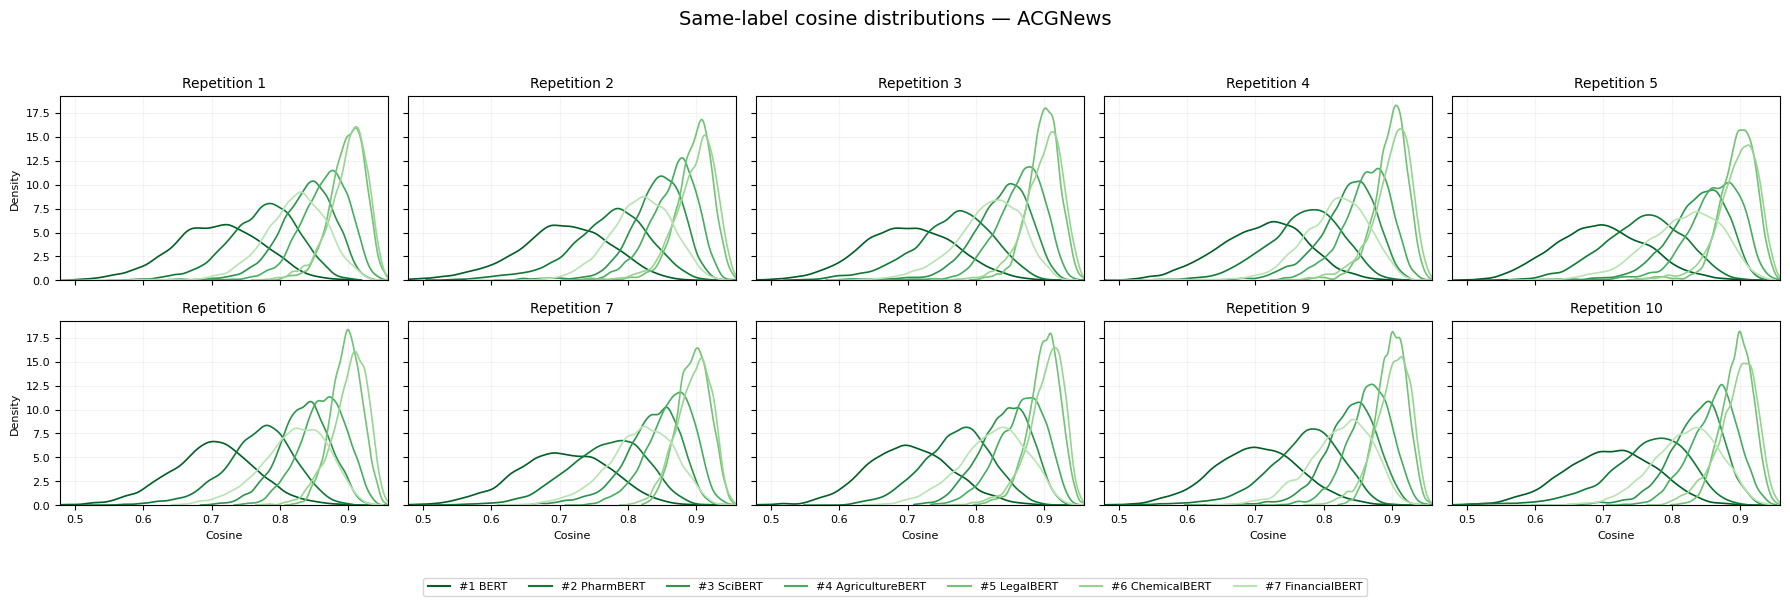

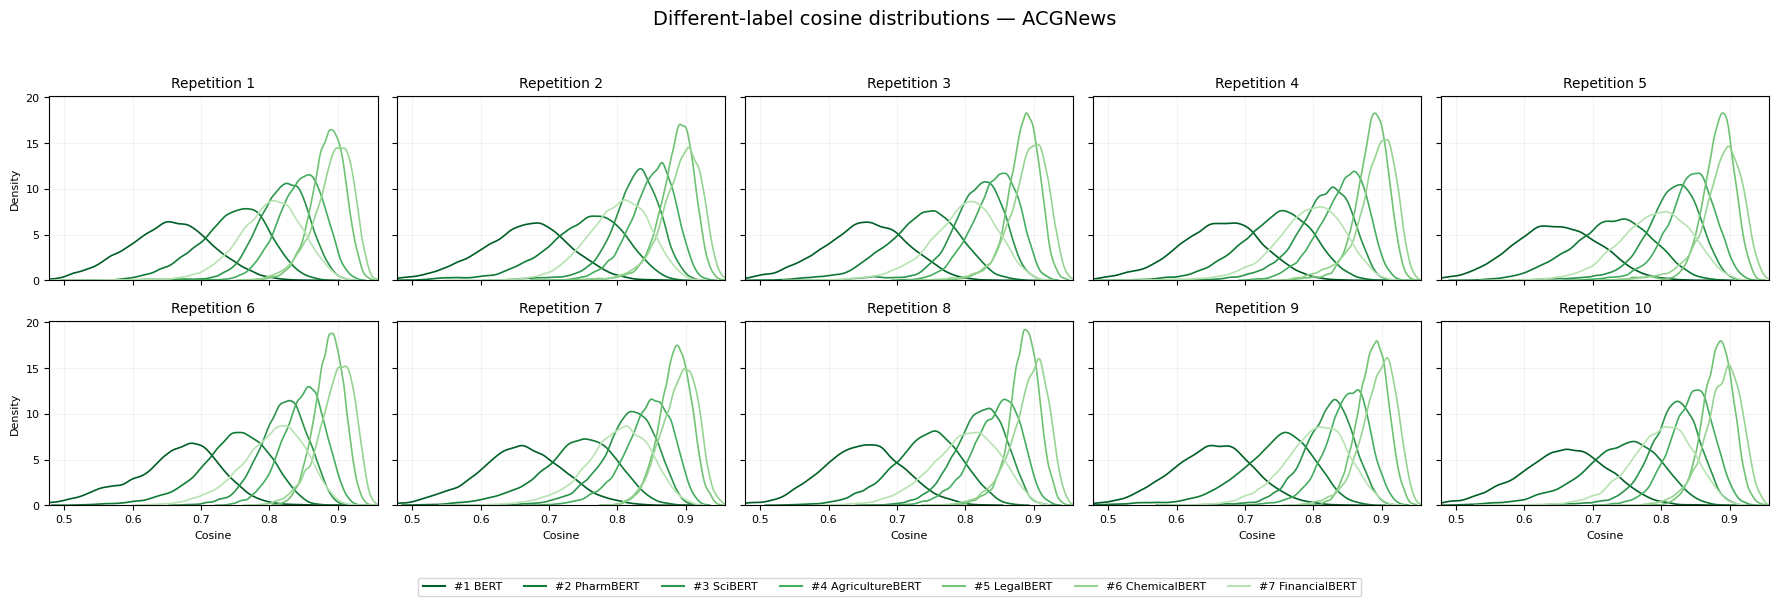

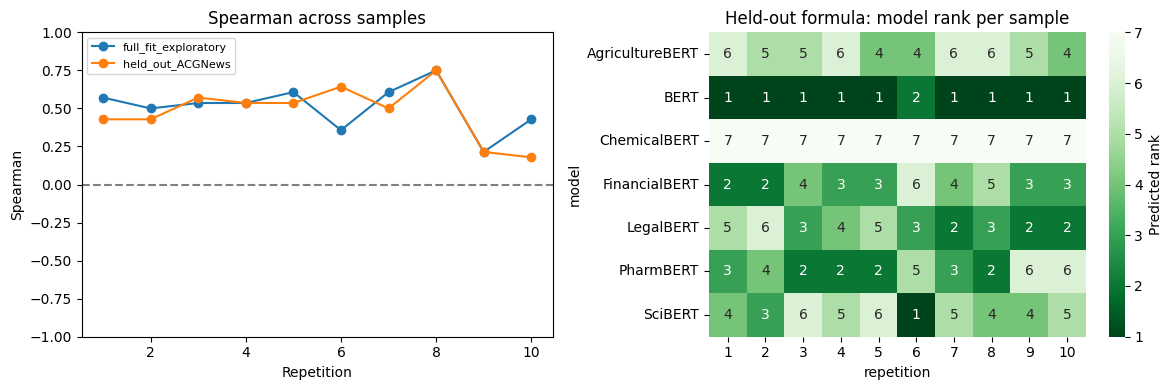

COMPLETED: 10 repetitions, 70 model runs. Results: /home/amyliu/Desktop/GR/ACGNews/results/uncertainty10_gpu_20261025_174025


In [24]:
from matplotlib.lines import Line2D
name_to_checkpoint = {v:k for k,v in MODEL_NAMES.items()}
real_ranks = dict(zip(order, actual))
colors = {name:plt.cm.Greens(np.interp(real_ranks[name],[1,7],[.92,.30])) for name in order}
all_scores = np.concatenate([np.asarray(result[key],dtype=float)
    for result in results["full_results"].values() for key in ["same_scores","diff_scores_original"]])
xmin = max(-1, np.quantile(all_scores,.001)-.01)
xmax = min(1, np.quantile(all_scores,.999)+.01)
for key, title, filename in [
    ("same_scores","Same-label cosine distributions","same_label_all_10_repetitions.png"),
    ("diff_scores_original","Different-label cosine distributions","different_label_all_10_repetitions.png")]:
    fig, axes = plt.subplots(2,5,figsize=(18,6),sharex=True,sharey=True)
    for rep, ax in enumerate(axes.flat,start=1):
        for name in sorted(order,key=real_ranks.get):
            values = np.asarray(results["full_results"][(rep,name_to_checkpoint[name])][key],dtype=float)
            sns.kdeplot(x=values,ax=ax,color=colors[name],bw_adjust=.8,clip=(-1,1),cut=0,linewidth=1.2)
        ax.set_title(f"Repetition {rep}",fontsize=10)
        ax.set_xlim(xmin,xmax);ax.set_xlabel("Cosine",fontsize=8);ax.set_ylabel("Density",fontsize=8)
        ax.tick_params(labelsize=8);ax.grid(alpha=.15)
    fig.suptitle(title+" — ACGNews",fontsize=14)
    fig.legend(handles=[Line2D([0],[0],color=colors[name],label=f"#{int(real_ranks[name])} {name}")
        for name in sorted(order,key=real_ranks.get)],loc="lower center",ncol=7,fontsize=8)
    fig.tight_layout(rect=[0,.07,1,.95])
    fig.savefig(OUTPUT_DIR / filename,dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)
fig, axes=plt.subplots(1,2,figsize=(12,4))
for procedure,g in round_df.groupby("procedure"):
    axes[0].plot(g.repetition,g.spearman,marker="o",label=procedure)
axes[0].axhline(0,color="gray",linestyle="--");axes[0].set_ylim(-1,1)
axes[0].set(xlabel="Repetition",ylabel="Spearman",title="Spearman across samples");axes[0].legend(fontsize=8)
rank_matrix=score_df.query('procedure == "held_out_ACGNews"').pivot(index="model",columns="repetition",values="predicted_rank")
sns.heatmap(rank_matrix,annot=True,fmt=".0f",cmap="Greens_r",vmin=1,vmax=7,ax=axes[1],cbar_kws={"label":"Predicted rank"})
axes[1].set_title("Held-out formula: model rank per sample")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "combination_stability.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
print("COMPLETED: 10 repetitions, 70 model runs. Results:", OUTPUT_DIR.resolve())


### Real embeddings: pair checks and shuffled-label control

,raw_same_mean,raw_diff_mean,raw_mean_gap,overall_pair_mean,permuted_gap_mean,permuted_gap_std,sample_duplicate_texts
model,,,,,,,
AgricultureBERT,0.863784,0.845188,0.018595,0.849837,-0.000005,0.000574,0.0
BERT,0.703229,0.654413,0.048816,0.666624,0.000010,0.001119,0.0
ChemicalBERT,0.898410,0.892175,0.006235,0.893734,0.000003,0.000465,0.0
FinancialBERT,0.820014,0.798084,0.021930,0.803569,-0.000005,0.000806,0.0
LegalBERT,0.897520,0.885161,0.012359,0.888251,-0.000001,0.000377,0.0
PharmBERT,0.767800,0.741130,0.026669,0.747798,0.000036,0.000938,0.0
SciBERT,0.836564,0.817613,0.018951,0.822351,0.000007,0.000640,0.0


PASS: all 70 saved same/different distributions match direct class-equality masks.
Permutation is descriptive: document length/topic confounding is not controlled.


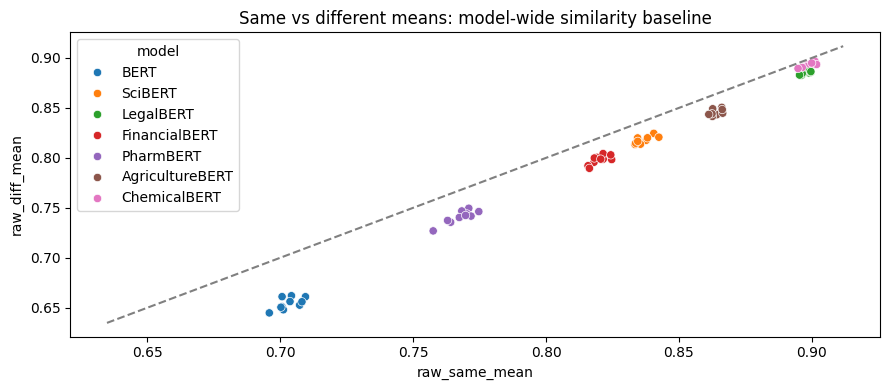

In [25]:
# Raw mean diagnostics and a label-permutation control use saved embeddings only.
# Do not rerun the transformer or alter the main metrics.
audit_rows = []
for (rep,checkpoint), result in results["full_results"].items():
    labels = np.array([row[0] for row in result["labels"]])
    embeddings = result["embeddings"].detach().cpu().float()
    normalized = F.normalize(embeddings,p=2,dim=1)
    matrix = (normalized @ normalized.T).numpy()
    ii,jj = np.triu_indices(len(labels),k=1)
    values = matrix[ii,jj]; mask = labels[ii] == labels[jj]
    np.testing.assert_allclose(values[mask],result["same_scores"],atol=1e-6,rtol=1e-5)
    np.testing.assert_allclose(values[~mask],result["diff_scores_original"],atol=1e-6,rtol=1e-5)
    rng = np.random.default_rng(int(result["summary"]["random_seed"]))
    null_gaps = []
    for _ in range(200):
        shuffled = rng.permutation(labels)
        shuffled_same = shuffled[ii] == shuffled[jj]
        null_gaps.append(values[shuffled_same].mean()-values[~shuffled_same].mean())
    audit_rows.append(dict(repetition=rep,model=MODEL_NAMES[checkpoint],
        raw_same_mean=values[mask].mean(),raw_diff_mean=values[~mask].mean(),
        raw_mean_gap=values[mask].mean()-values[~mask].mean(),
        overall_pair_mean=values.mean(),permuted_gap_mean=np.mean(null_gaps),
        permuted_gap_std=np.std(null_gaps,ddof=1),
        sample_duplicate_texts=int(result["sampled_df"][TEXT_COL].duplicated().sum())))
pair_audit_df = pd.DataFrame(audit_rows)
pair_audit_df.to_csv(OUTPUT_DIR / "pair_and_permutation_diagnostics.csv",index=False)
display(Markdown("### Real embeddings: pair checks and shuffled-label control"))
display(pair_audit_df.groupby("model").mean(numeric_only=True).drop(columns="repetition").round(6))
print("PASS: all 70 saved same/different distributions match direct class-equality masks.")
print("Permutation is descriptive: document length/topic confounding is not controlled.")
fig,ax=plt.subplots(figsize=(9,4))
sns.scatterplot(data=pair_audit_df,x="raw_same_mean",y="raw_diff_mean",hue="model",ax=ax)
lo=min(pair_audit_df.raw_same_mean.min(),pair_audit_df.raw_diff_mean.min())-.01
hi=max(pair_audit_df.raw_same_mean.max(),pair_audit_df.raw_diff_mean.max())+.01
ax.plot([lo,hi],[lo,hi],linestyle="--",color="gray")
ax.set_title("Same vs different means: model-wide similarity baseline")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "same_vs_different_mean_diagnostic.png",dpi=180)
plt.show();plt.close(fig)
